# Imports and set up

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats.contingency import association

from churn.config import SEED, TARGET, RAW_PATH, CAT_COLS
from churn.data import load_raw, clean

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

## Load, clean and read data

In [13]:
df = clean(load_raw(RAW_PATH))

print("================ Shape ================")
print(df.shape)

print("================ Info ================")
print(df.info())

print("================ Describe ================")
print(df.describe())

print("================ Duplicates ================")
print(df.duplicated().sum())

print("================ Missing values ================")
print(df.isna().sum())

print("================ Target imbalance ================")
print(df[TARGET].value_counts(normalize=True))

================ Shape ================
(7043, 21)
================ Info ================
<class 'pandas.DataFrame'>
Index: 7043 entries, 3668-QPYBK to 3186-AJIEK
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Gender             7043 non-null   category
 1   Senior Citizen     7043 non-null   category
 2   Partner            7043 non-null   category
 3   Dependents         7043 non-null   category
 4   Tenure Months      7043 non-null   int64   
 5   Phone Service      7043 non-null   category
 6   Multiple Lines     7043 non-null   category
 7   Internet Service   7043 non-null   category
 8   Online Security    7043 non-null   category
 9   Online Backup      7043 non-null   category
 10  Device Protection  7043 non-null   category
 11  Tech Support       7043 non-null   category
 12  Streaming TV       7043 non-null   category
 13  Streaming Movies   7043 non-null   category
 14  Contract       

In [14]:
for col in CAT_COLS:
    v = association(pd.crosstab(df[col], df[TARGET]), method="cramer")
    print(f"{col:20s} V={v:.3f}")

Gender               V=0.009
Senior Citizen       V=0.151
Partner              V=0.150
Dependents           V=0.249
Phone Service        V=0.012
Multiple Lines       V=0.040
Internet Service     V=0.322
Online Security      V=0.347
Online Backup        V=0.292
Device Protection    V=0.282
Tech Support         V=0.343
Streaming TV         V=0.231
Streaming Movies     V=0.231
Contract             V=0.410
Paperless Billing    V=0.192
Payment Method       V=0.303


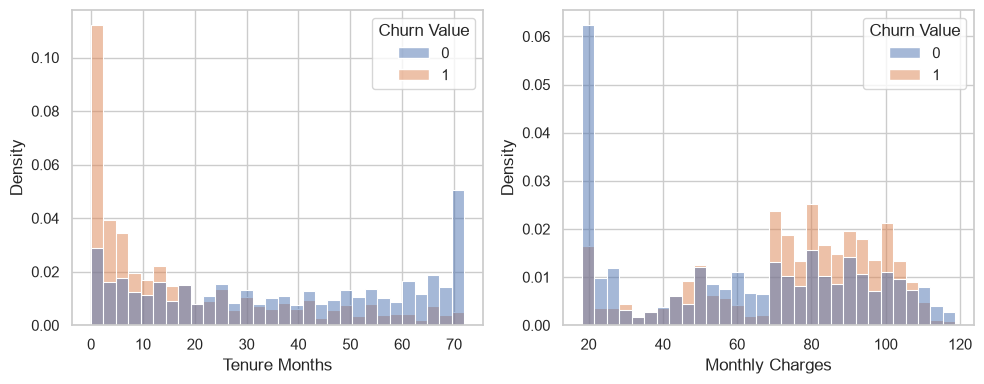

Tenure Months        Monthly Charges       
                     mean median            mean median
Churn Value                                            
0                    37.6   38.0            61.3   64.4
1                    18.0   10.0            74.4   79.6

In [15]:
num_cols = ["Tenure Months", "Monthly Charges"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, stat='density', common_norm=False, ax=ax)
plt.tight_layout()
plt.show()

df.groupby(TARGET)[num_cols].agg(["mean", "median"]).round(1)

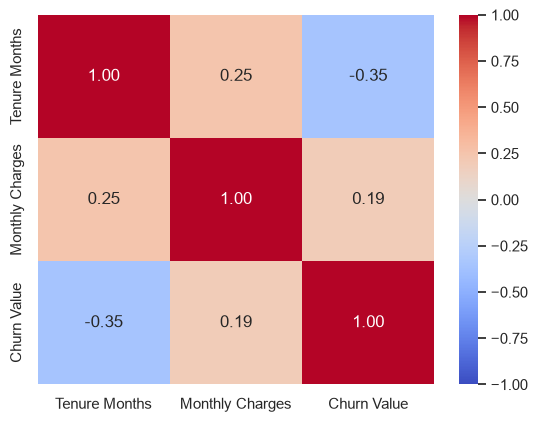

In [16]:
num_cols = ["Tenure Months", "Monthly Charges"]

sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

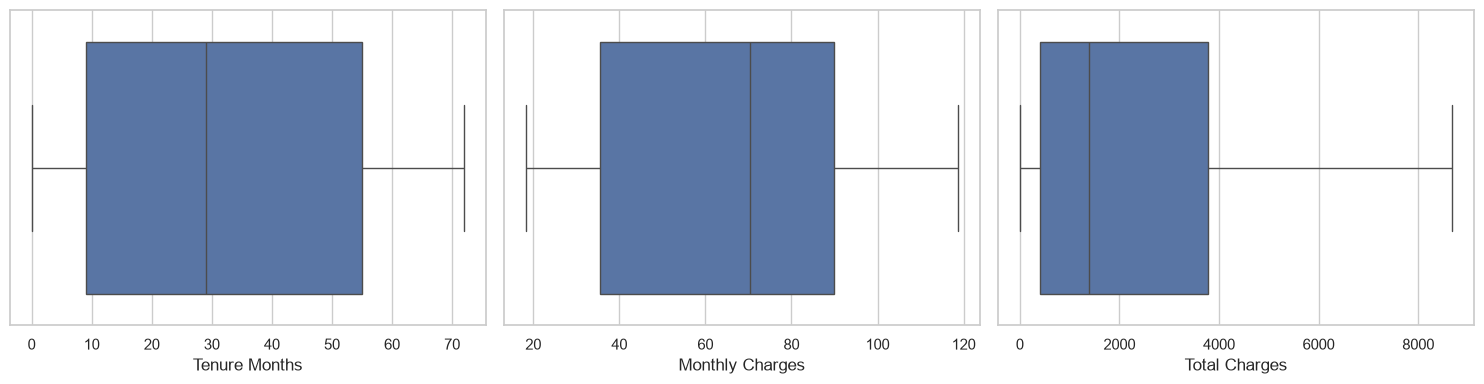

Tenure Months      outliers by IQR rule: 0
Monthly Charges    outliers by IQR rule: 0
Total Charges      outliers by IQR rule: 0


In [17]:
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x=col, ax=ax)
plt.tight_layout()
plt.show()

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:18s} outliers by IQR rule: {n_out}")